# 05 · Spatial EDA and player heatmaps

**Question: where are players operating?**

Every StatsBomb event has a location, so every player has a spatial
footprint. This notebook builds the spatial toolkit used by the app
(`barca.analytics.spatial`) and applies it:

* action heatmaps with **action filters** (all, touches, passes, carries,
  attacking, defending) and **time filters** (match, last 5, last 10,
  season);
* zone metrics: average position, thirds, channels, box involvement and
  positional spread;
* Barcelona's occupation of the positional-play grid against the league;
* a first look at 360 freeze frames.

> **Terminology.** These are **event (action) heatmaps**. They show where a
> player *did something recorded*: passed, carried, received, pressed,
> tackled. They are not physical coverage maps: a player walking back into
> position generates no event. True coverage needs tracking data, which the
> open data does not include.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.ndimage import gaussian_filter

from barca import config, pipeline
from barca.analytics import definitions as D
from barca.analytics import spatial
from barca.data import normalize
from barca.visualization import pitch as vp
from barca.visualization import style

style.apply()
pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(2)

matches = normalize.matches(pl.read_parquet(config.INTERIM / "matches.parquet"))
events = normalize.events(pipeline.scan_events())
lineups = pl.read_parquet(config.INTERIM / "lineups.parquet")
names = lineups.select("player_id", pl.coalesce("nickname", "player").alias("name")).unique("player_id")
barca_ev = (
    events.filter(pl.col("team") == "Barcelona", pl.col("player_id").is_not_null())
    .join(matches.select("match_id", "date", "kickoff").lazy(), on="match_id")
    .collect()
    .join(names, on="player_id", how="left")
)
print(f"Barcelona player events: {barca_ev.height:,}")


def smooth_heatmap(ax, frame, title, bins=(24, 16), sigma=1.0, cmap=None):
    p = vp.pitch(line_zorder=2, line_color="#8f8e88")
    p.draw(ax=ax)
    stats_ = p.bin_statistic(frame["x"].to_numpy(), frame["y"].to_numpy(), statistic="count", bins=bins)
    total = stats_["statistic"].sum()
    stats_["statistic"] = gaussian_filter(stats_["statistic"], sigma) / max(total, 1)
    p.heatmap(stats_, ax=ax, cmap=cmap or style.HEAT, edgecolors="none", zorder=1)
    ax.set_title(title, fontsize=10, loc="left", pad=4)

Barcelona player events: 1,232,523


## 1. One player, three eras

Messi's touches (all on-ball actions) in three seasons: under Rijkaard as a
right winger, under Guardiola as a false nine, and in his final season.

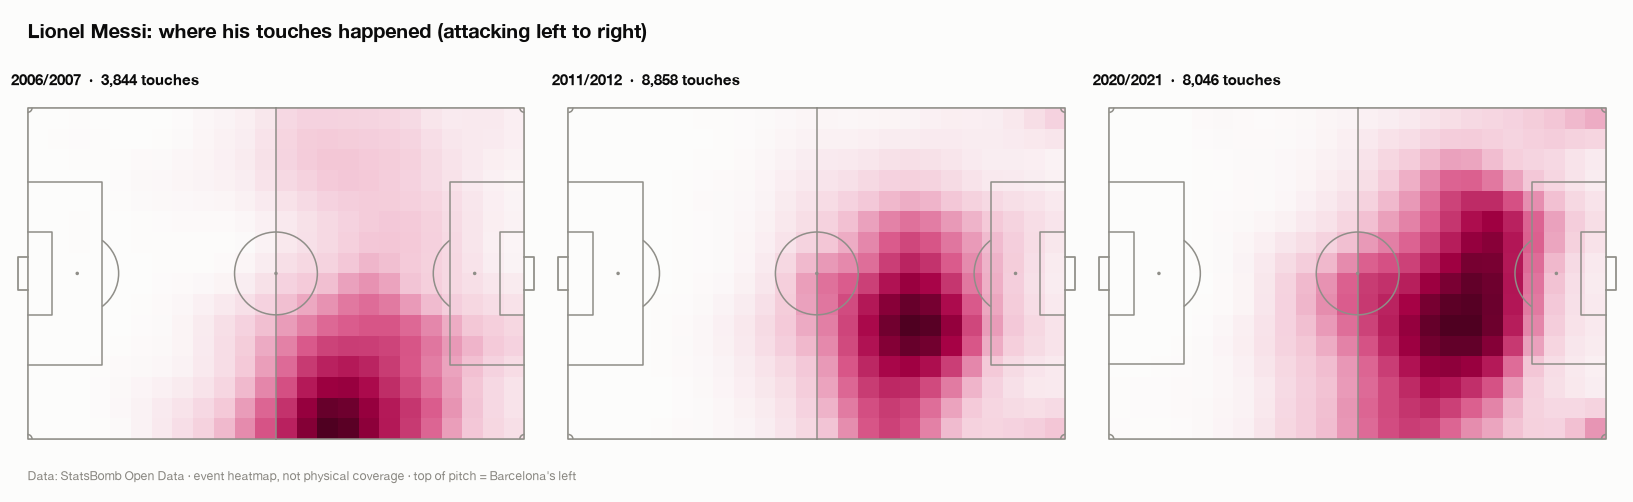

In [2]:
messi_id = names.filter(pl.col("name") == "Lionel Messi")["player_id"][0]
messi = barca_ev.filter(pl.col("player_id") == messi_id)
p = vp.pitch()
fig, axs = p.grid(nrows=1, ncols=3, figheight=4.6, title_height=0.08, endnote_height=0.06, axis=False, grid_height=0.72,
                  space=0.06, title_space=0.08)
for ax, season in zip(axs["pitch"], ["2006-2007", "2011-2012", "2020-2021"], strict=True):
    frame = spatial.filter_actions(messi.filter(pl.col("season") == season), "touches")
    smooth_heatmap(ax, frame, f"{season.replace('-', '/')}  ·  {frame.height:,} touches")
axs["title"].text(0, 0.5, "Lionel Messi: where his touches happened (attacking left to right)", fontsize=13,
                  fontweight="bold", va="center")
axs["endnote"].text(0, 0.5, style.STATSBOMB_CREDIT + " · event heatmap, not physical coverage · top of pitch = Barcelona's left",
                    fontsize=8, color=style.MUTED, va="center")
style.savefig(fig, "05_messi_eras")
plt.show()

In [3]:
profiles = []
for season in ["2006-2007", "2011-2012", "2020-2021"]:
    prof = spatial.spatial_profile(spatial.filter_actions(messi.filter(pl.col("season") == season), "touches"))
    profiles.append({"season": season, **prof})
pl.DataFrame(profiles).select("season", "n", "avg_x", "avg_y", "attacking_third", "left", "centre", "right",
                              "box_share", "ellipse_area")

season,n,avg_x,avg_y,attacking_third,left,centre,right,box_share,ellipse_area
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""2006-2007""",3844,79.37,52.18,0.49,0.20,0.16,0.64,0.06,1256.46
"""2011-2012""",8858,81.15,48.63,0.54,0.16,0.32,0.51,0.07,936.20
"""2020-2021""",8046,80.03,45.74,0.53,0.22,0.33,0.45,0.06,1096.54


The heatmaps show the migration that defined an era. In 2006/07 the mass
sits on the **right wing**: 64% of his touches in the right channels and
only 16% central (y = 0 is the team's left, so the right is at the
bottom). By 2011/12, as a false nine, his central share has **doubled** to
32%, his average touch is furthest forward and his footprint most compact
(smallest ellipse). By 2020/21 he is slightly deeper and more central still,
with a broader footprint again: a playmaker's map. The share of touches
inside the box barely changes (6-7%). Messi touched the ball so often
everywhere that the box is always a small fraction of it.

## 2. Action filters

The same player and season, filtered to different kinds of action. This is
the filter set the app offers.

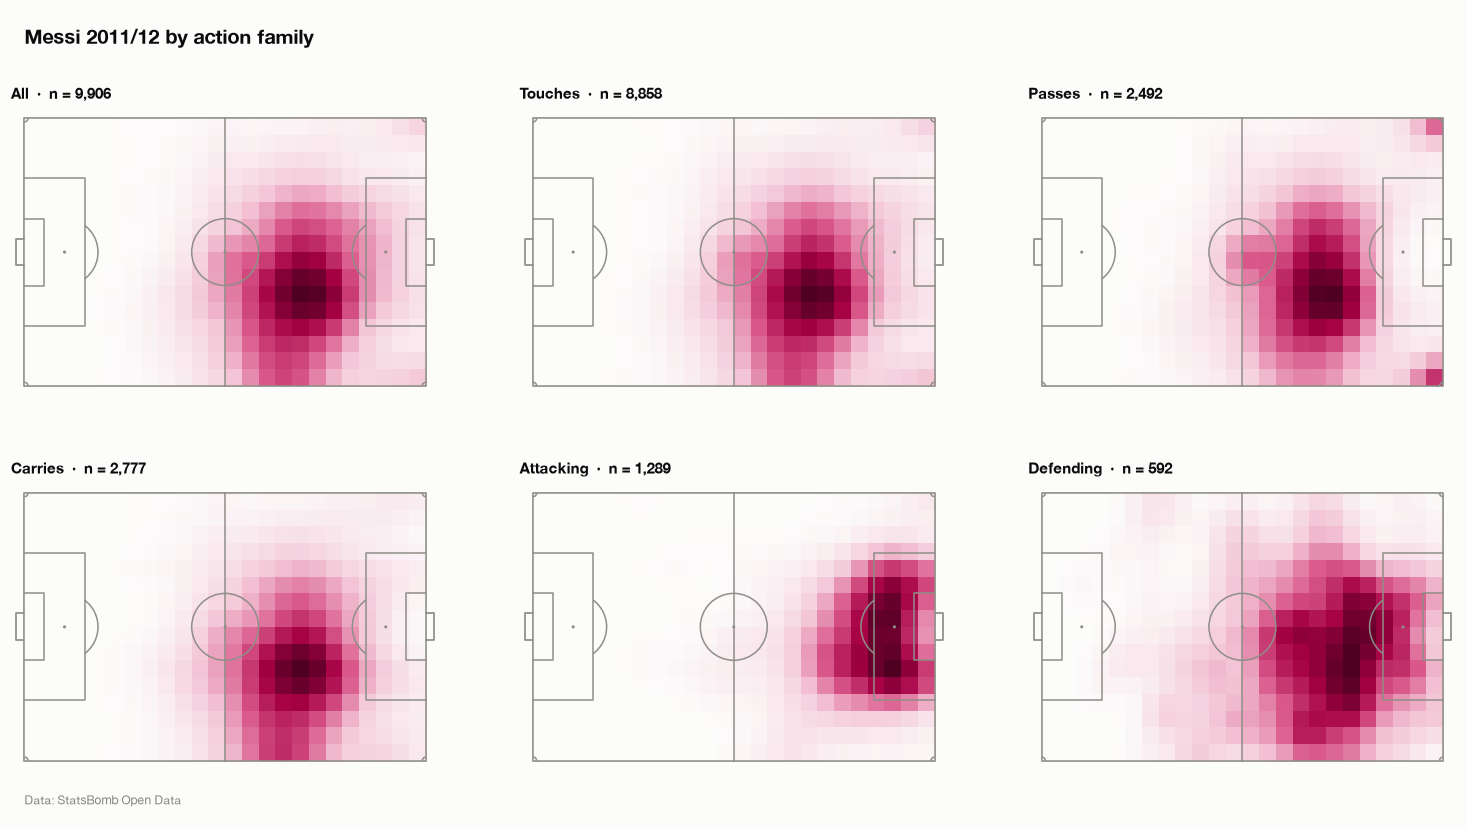

In [4]:
season = messi.filter(pl.col("season") == "2011-2012")
families = ["all", "touches", "passes", "carries", "attacking", "defending"]
p = vp.pitch()
fig, axs = p.grid(nrows=2, ncols=3, figheight=7.8, title_height=0.06, endnote_height=0.04, axis=False,
                  grid_height=0.78, space=0.12, title_space=0.05)
for ax, fam in zip(axs["pitch"].flat, families, strict=True):
    frame = spatial.filter_actions(season, fam)
    smooth_heatmap(ax, frame, f"{fam.title()}  ·  n = {frame.height:,}")
axs["title"].text(0, 0.5, "Messi 2011/12 by action family", fontsize=13, fontweight="bold", va="center")
axs["endnote"].text(0, 0.5, style.STATSBOMB_CREDIT, fontsize=8, color=style.MUTED, va="center")
style.savefig(fig, "05_action_filters")
plt.show()

Filters change the story. Passes and carries reveal the build-up role from
the right half-space, dropping towards the centre circle. *Attacking*
actions collapse onto the penalty area and its edge, centrally and to the
right. *Defending* actions sit almost entirely in the opponent's half:
pressures after losing the ball, never deep defending.

## 3. Time filters

Heatmaps for Pedri (2020/21) over four windows, using only matches before a
chosen date, the same `as_of` logic the app uses.

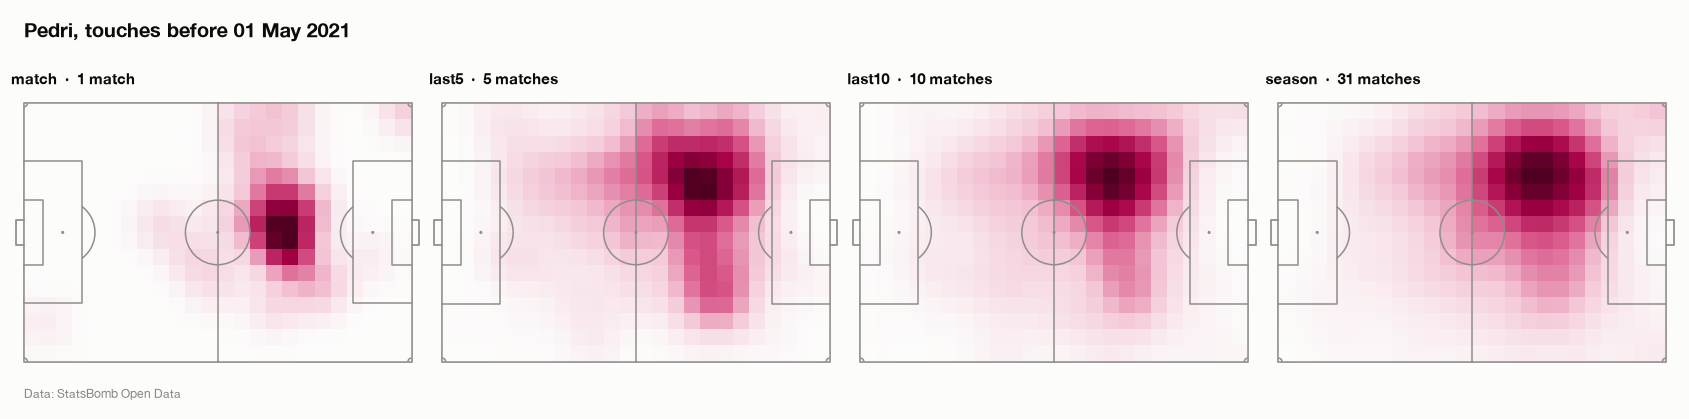

In [5]:
pedri_id = names.filter(pl.col("name") == "Pedri")["player_id"][0]
pedri_matches = (
    barca_ev.filter(pl.col("player_id") == pedri_id)
    .select("match_id", "date", "kickoff", "season").unique().sort("kickoff")
    .with_columns(pl.col("season").str.replace("-", "/"))
)
as_of = date(2021, 5, 1)
windows = ["match", "last5", "last10", "season"]
p = vp.pitch()
fig, axs = p.grid(nrows=1, ncols=4, figheight=3.8, title_height=0.09, endnote_height=0.07, axis=False,
                  grid_height=0.68, space=0.05, title_space=0.1)
for ax, w in zip(axs["pitch"], windows, strict=True):
    ids = spatial.window_matches(pedri_matches, as_of=as_of, window=w)
    frame = spatial.filter_actions(barca_ev.filter(pl.col("player_id") == pedri_id, pl.col("match_id").is_in(ids)), "touches")
    smooth_heatmap(ax, frame, f"{w}  ·  {len(ids)} match{'es' if len(ids) != 1 else ''}", sigma=1.2)
axs["title"].text(0, 0.5, f"Pedri, touches before {as_of:%d %b %Y}", fontsize=13, fontweight="bold", va="center")
axs["endnote"].text(0, 0.5, style.STATSBOMB_CREDIT, fontsize=8, color=style.MUTED, va="center")
style.savefig(fig, "05_time_filters")
plt.show()

A single match is noisy; five matches already show the stable left
half-space role; ten and the season barely change it. That is useful for
the app's defaults (last 5 is responsive yet stable) and for features: a
player's *role* is stable over a few matches, while his *output* is not.

## 4. Zone metrics for the core squad

Spatial profiles for players with ≥ 5,000 minutes of touches across the
data. `left`/`right` combine the wing and half-space channels.

In [6]:
touch_ev = spatial.filter_actions(barca_ev, "touches")
counts = touch_ev.group_by("player_id").agg(pl.len().alias("n")).filter(pl.col("n") >= 5000)
rows = []
for pid in counts["player_id"]:
    frame = touch_ev.filter(pl.col("player_id") == pid)
    rows.append({"name": frame["name"][0], **spatial.spatial_profile(frame)})
zone_table = pl.DataFrame(rows).sort("avg_x")
zone_table.select("name", "n", "avg_x", "avg_y", "defensive_third", "middle_third", "attacking_third",
                  "left", "centre", "right", "box_share", "spread_x", "spread_y")

name,n,avg_x,avg_y,defensive_third,middle_third,attacking_third,left,centre,right,box_share,spread_x,spread_y
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Marc-André ter Stegen""",15797,9.72,39.91,1.00,0.00,0.00,0.08,0.84,0.08,0.00,7.43,7.39
"""Claudio Bravo""",5067,10.32,39.57,1.00,0.00,0.00,0.11,0.80,0.09,0.00,7.52,8.40
"""Víctor Valdés""",17327,10.38,40.60,1.00,0.00,0.00,0.11,0.77,0.12,0.00,6.68,8.57
"""Gabriel Milito""",6556,41.04,24.85,0.49,0.50,0.02,0.73,0.23,0.04,0.01,16.85,11.58
"""Gerard Piqué""",59762,43.03,50.45,0.43,0.54,0.03,0.11,0.29,0.59,0.01,19.83,14.92
"""Marc Bartra""",5861,43.47,47.90,0.44,0.53,0.03,0.20,0.24,0.56,0.01,19.72,17.24
"""Carles Puyol""",25627,43.70,40.02,0.46,0.50,0.05,0.37,0.29,0.33,0.01,19.39,20.01
"""Samuel Umtiti""",14742,43.79,27.57,0.40,0.58,0.02,0.68,0.18,0.14,0.00,19.91,16.93
"""Rafael Márquez""",13305,43.86,49.97,0.44,0.52,0.03,0.12,0.31,0.57,0.01,18.56,15.37


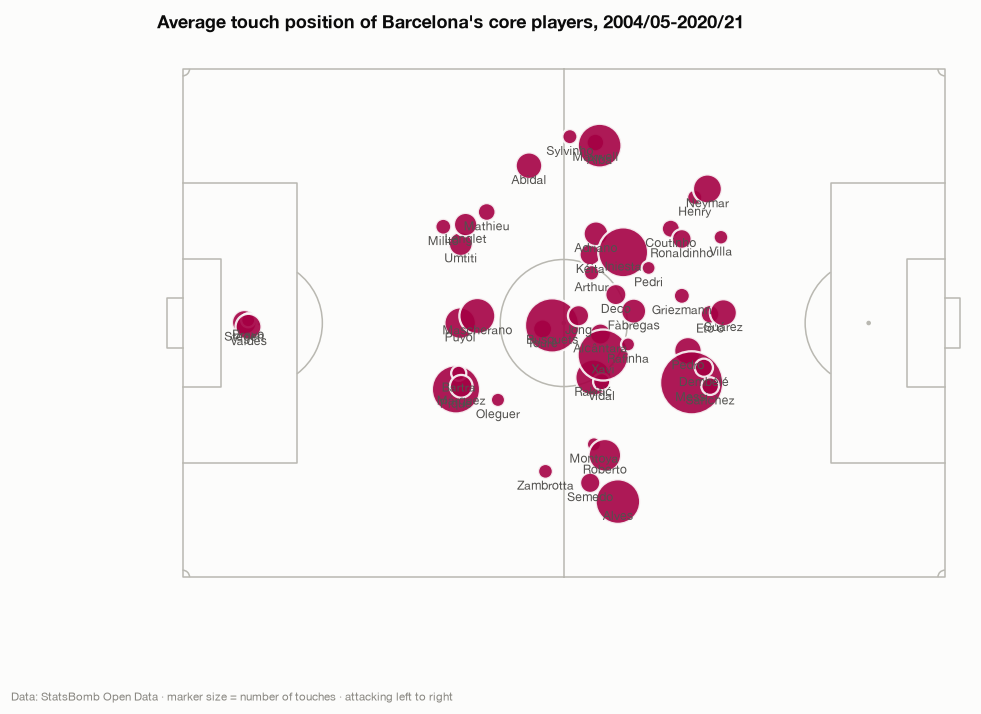

In [7]:
fig, ax = plt.subplots(figsize=(10, 6.6))
p = vp.pitch()
p.draw(ax=ax)
p.scatter(zone_table["avg_x"], zone_table["avg_y"], ax=ax, s=zone_table["n"] / 60, color=style.BARCA,
          edgecolor=style.SURFACE, linewidth=1.5, alpha=0.9, zorder=3)
for r in zone_table.iter_rows(named=True):
    ax.annotate(r["name"].split()[-1], (r["avg_x"], r["avg_y"]), xytext=(0, -12), textcoords="offset points",
                ha="center", fontsize=8, color=style.INK_2, zorder=4)
ax.set_title("Average touch position of Barcelona's core players, 2004/05-2020/21")
style.caption(ax, style.STATSBOMB_CREDIT + " · marker size = number of touches · attacking left to right")
style.savefig(fig, "05_average_positions")
plt.show()

Average positions reproduce the structure of the side:

* **Full-backs play as wingers in possession**: Dani Alves's average touch
  (x ≈ 68.5) is further upfield than Xavi's (≈ 66).
* **Busquets** (and Yaya Touré before him) is the deepest and most central
  midfielder, the pivot everything passes through.
* **Messi** sits right-of-centre and deeper than the out-and-out strikers
  (Suárez, Villa, Eto'o).

Positional spread quantifies roles. Full-backs have a large spread *along*
the pitch but very little across it: they own a narrow corridor. Centre-
backs have little lateral spread. The broadest footprints belong to wide
forwards who switched flanks (Pedro, Dembélé, Alexis) and to utility players
used in several positions (Adriano, Montoya, Sergi Roberto). Messi's
footprint is compact for a forward.

## 5. Barcelona's positional-play grid

Share of touches per zone for Barcelona vs every other team, 2015/16 (the
complete season), shown as the difference in percentage points.

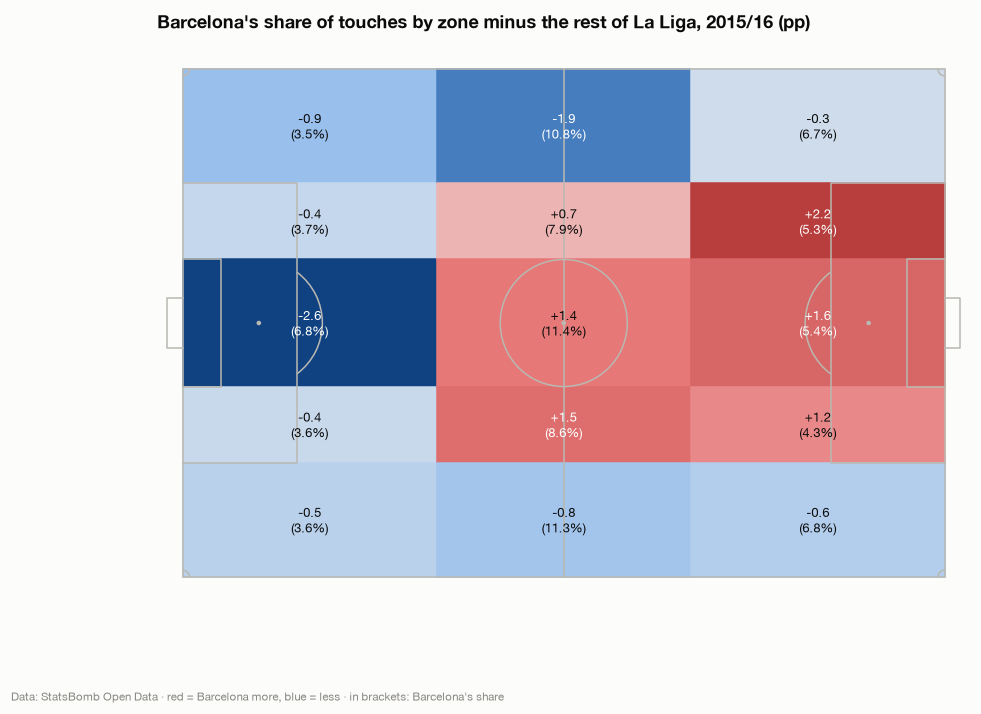

In [8]:
s1516 = spatial.with_zones(
    spatial.filter_actions(events.filter(pl.col("season") == "2015-2016"), "touches").collect()
).with_columns((pl.col("team") == "Barcelona").alias("barca"))
occ = (
    s1516.group_by("barca", "third", "channel").agg(pl.len().alias("n"))
    .with_columns((pl.col("n") / pl.col("n").sum().over("barca")).alias("share"))
)
pivot = occ.pivot(on="barca", index=["third", "channel"], values="share").rename({"true": "barca", "false": "league"})
pivot = pivot.with_columns(((pl.col("barca") - pl.col("league")) * 100).alias("diff_pp"))

grid_diff = np.zeros((3, 5))
grid_barca = np.zeros((3, 5))
for r in pivot.iter_rows(named=True):
    i, j = spatial.THIRDS.index(r["third"]), spatial.CHANNELS.index(r["channel"])
    grid_diff[i, j] = r["diff_pp"]
    grid_barca[i, j] = r["barca"] * 100

fig, ax = plt.subplots(figsize=(10, 6.6))
p = vp.pitch(line_zorder=3)
p.draw(ax=ax)
vmax = np.abs(grid_diff).max()
for i, (x0, x1) in enumerate(zip(spatial.THIRD_EDGES[:-1], spatial.THIRD_EDGES[1:], strict=True)):
    for j, (y0, y1) in enumerate(zip(spatial.CHANNEL_EDGES[:-1], spatial.CHANNEL_EDGES[1:], strict=True)):
        colour = style.DIVERGING(0.5 + grid_diff[i, j] / (2 * vmax))
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, color=colour, zorder=1))
        ink = "white" if abs(grid_diff[i, j]) > 0.55 * vmax else style.INK
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, f"{grid_diff[i, j]:+.1f}\n({grid_barca[i, j]:.1f}%)", ha="center",
                va="center", fontsize=8.5, color=ink, zorder=4)
ax.set_title("Barcelona's share of touches by zone minus the rest of La Liga, 2015/16 (pp)")
style.caption(ax, style.STATSBOMB_CREDIT + " · red = Barcelona more, blue = less · in brackets: Barcelona's share")
style.savefig(fig, "05_positional_grid")
plt.show()

About 5 percentage points of Barcelona's touches move out of their own
defensive third, compared with the rest of the league, and roughly 4 points
move into the **attacking third**. The gain is concentrated in the
**half-spaces and the centre**, the zones between the lines. The *wide*
zones of the middle third are used *less* than by other teams: build-up
goes through the middle, and width is only used high up the pitch. It is
the statistical fingerprint of positional play: territory, and occupation of
the zones between the lines.

## 6. A look at 360 data

In 2020/21 each event carries a freeze frame of the visible players. One
Barcelona final-third pass, with every visible player:

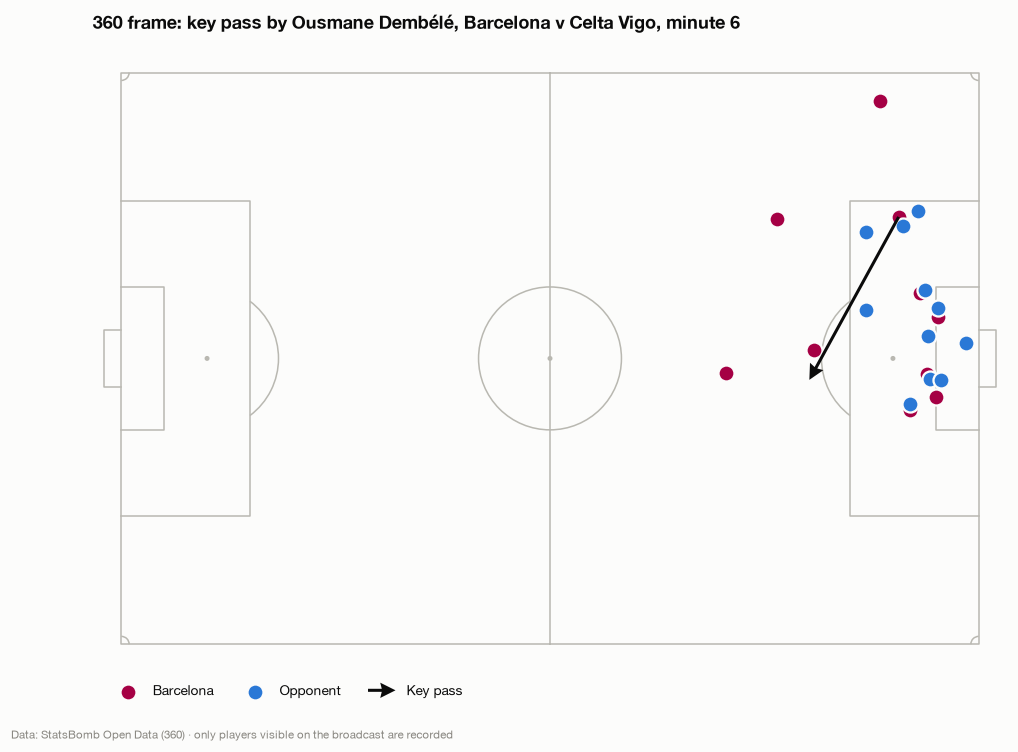

In [9]:
ts = pl.read_parquet(config.INTERIM / "three_sixty.parquet")
cand = (
    events.filter(pl.col("season") == "2020-2021", pl.col("team") == "Barcelona", D.PASS_COMPLETE,
                  pl.col("x") > 85, pl.col("pass_shot_assist").fill_null(False))
    .select("match_id", "event_id", "player", "x", "y", "end_x", "end_y", "minute")
    .collect()
)
frame_sizes = ts.group_by("event_id").agg(pl.len().alias("visible"))
cand = cand.join(frame_sizes, on="event_id").sort("visible", descending=True)
ev0 = cand.row(0, named=True)
ff = ts.filter(pl.col("event_id") == ev0["event_id"])
p = vp.pitch()
fig, ax = p.draw(figsize=(10, 6.6))
team_ff = ff.filter(pl.col("teammate"))
opp_ff = ff.filter(~pl.col("teammate"))
p.scatter(team_ff["x"], team_ff["y"], ax=ax, s=110, color=style.BARCA, edgecolor=style.SURFACE, linewidth=1.5,
          label="Barcelona", zorder=3)
p.scatter(opp_ff["x"], opp_ff["y"], ax=ax, s=110, color=style.OPPONENT, edgecolor=style.SURFACE, linewidth=1.5,
          label="Opponent", zorder=3)
p.arrows(ev0["x"], ev0["y"], ev0["end_x"], ev0["end_y"], ax=ax, color=style.INK, width=2, headwidth=5,
         headlength=5, zorder=4, label="Key pass")
ax.legend(loc="lower left", ncols=3, bbox_to_anchor=(0.01, -0.06))
mi = matches.filter(pl.col("match_id") == ev0["match_id"]).row(0, named=True)
ax.set_title(f"360 frame: key pass by {ev0['player'].split()[0]} {ev0['player'].split()[-1]}, "
             f"{mi['home']} v {mi['away']}, minute {ev0['minute']}")
style.caption(ax, style.STATSBOMB_CREDIT + " (360) · only players visible on the broadcast are recorded")
style.savefig(fig, "05_360_frame")
plt.show()

In [10]:
# How crowded is the space around Barcelona's final-third passes?
fp = (
    events.filter(pl.col("season") == "2020-2021", pl.col("team") == "Barcelona", D.PASS, pl.col("x") >= 80)
    .select("event_id", pl.col("x").alias("bx"), pl.col("y").alias("by"), pl.col("outcome").is_null().alias("complete"))
    .collect()
    .join(ts.filter(~pl.col("teammate")), on="event_id")
    .with_columns((((pl.col("x") - pl.col("bx")) ** 2 + (pl.col("y") - pl.col("by")) ** 2).sqrt() <= 10).alias("close"))
    .group_by("event_id", "complete")
    .agg(pl.col("close").sum().alias("opponents_within_10y"))
)
fp.group_by("opponents_within_10y").agg(pl.len().alias("passes"), pl.col("complete").mean().alias("completion")).sort(
    "opponents_within_10y"
).head(7)

opponents_within_10y,passes,completion
u32,u32,f64
0,376,0.76
1,1875,0.85
2,2081,0.85
3,1539,0.86
4,919,0.81
5,469,0.72
6,206,0.72


With 360 frames, pass difficulty can be measured directly. Completion of
Barcelona's final-third passes is highest (≈85%) with one to three opponents
within 10 yards and drops to ≈72% with five or more. Passes with *nobody*
nearby are also completed less often (≈76%): they are mostly crosses and
long balls from isolated wide positions, a reminder that pressure alone
does not describe difficulty. The data covers one season and the visible
area only, so it is not used in any model, but it shows what the next level
of analysis would look like.

## Findings

1. **Heatmaps capture roles and role changes**, from Messi's winger → false
   nine → playmaker arc to full-backs whose average touch is further
   upfield than a central midfielder's.
2. **Action filters matter**: the same player looks different through
   passes, carries, attacking and defensive actions. The app exposes them.
3. **Roles stabilise within ~5 matches**, so "last 5" is a good default
   window, and spatial role features can be computed on short windows.
4. **Barcelona's positional-play fingerprint is measurable**: more touches in
   the attacking third, concentrated in the half-spaces and centre, and
   fewer in the wide build-up zones.
5. **Terminology stays honest**: event heatmaps, not coverage maps.

Next: comparing Barcelona with their opponents (`06_opposition_eda`).